<a href="https://colab.research.google.com/github/nidharmalik/digital-speech-analyzer/blob/main/VOiCES_Event_Detection_VAD_Arabic_Explained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Speech Processing
## VOiCES: Background Sound Classification & Voice Activity Detection



**هدف :** (أ) تمييز أربع فئات من الخلفيات الصوتية في التسجيلات باستخدام خصائص MFCC ونموذجي Random Forest وSVM، و(ب) تحديد فترات الكلام المحتمل باستخدام RMS وWebRTC VAD.

**طريقة قراءة الدفتر:** اقرأ شرح كل مرحلة، ثم خلية الكود التالية ونتائجها المحفوظة. حافظنا على جميع الأكواد ومخرجاتها الأصلية دون تغيير. **الأرقام الواردة في الشروح مستندة إلى مخرجات هذا الدفتر كما أُرسل.**

> **تنبيه عند إعادة التشغيل:** خلايا هذا الدفتر مترابطة وتعتمد على متغيرات المراحل السابقة. نفّذ الخلايا بالترتيب من الأعلى إلى الأسفل، وتأكد من توفر ملفات البيانات في بيئة Colab.


## خريطة العمل

| الجزء | المراحل | ما الذي سنحصل عليه؟ |
|---|---|---|
| تجهيز البيانات | تحميل المستودع، فحص CSV وTAR، قراءة WAV | فهرس التسجيلات وتسميات الخلفيات |
| التصنيف | MFCC، تنظيف، تقسيم بحسب المتحدث، RF وSVM | Accuracy وF1 وConfusion Matrix |
| كشف الكلام | RMS وWebRTC، مقارنة، فترات زمنية وتنظيف | مناطق Speech / Non-Speech محتملة |
| التقرير | عرض الجداول والقيود العلمية | نتائج جاهزة للتفسير والتوثيق |


## الخطوة 1 — تحميل مجموعة VOiCES-subset
**الهدف:** نسخ المستودع من GitHub إلى بيئة Google Colab.

- `git clone` ينزّل ملفات المشروع، و`%cd` يغيّر مجلد العمل الحالي.
- **الناتج المحفوظ:** اكتمل تحميل المستودع وظهرت رسالة نجاح.
- **مهم:** إذا أعدت تشغيل الجلسة وفُقد مجلد `/content/VOiCES-subset`، نفّذ هذه الخلية مرة أخرى. إذا كان المجلد موجوداً فقد يرفض `git clone` تكرار النسخ؛ لا تحتاج إلى نسخه مرتين.


In [ ]:

# Download VOiCES-subset from GitHub
!git clone https://github.com/Lab41/VOiCES-subset.git

# Open the dataset folder
%cd /content/VOiCES-subset

print("Dataset repository downloaded successfully!")


Cloning into 'VOiCES-subset'...
remote: Enumerating objects: 43, done.
remote: Total 43 (delta 0), reused 0 (delta 0), pack-reused 43 (from 1)
Receiving objects: 100% (43/43), 365.23 MiB | 22.67 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Updating files: 100% (22/22), done.
/content/VOiCES-subset
Dataset repository downloaded successfully!


## الخطوة 2 — استكشاف ملفات المجموعة
**الهدف:** معرفة ما نُزّل قبل البدء بمعالجة الصوت.

- `os.listdir()` يعرض الملفات والمجلدات.
- **الناتج المحفوظ:** 16 عنصراً، منها ثمانية أرشيفات `VOiCES_90_1.tar` إلى `VOiCES_90_8.tar`، وملفات CSV وNotebooks تعليمية.
- الأرشيفات TAR حاويات لملفات الصوت، وليست بالضرورة ملفات WAV مكشوفة مباشرة في المجلد.


In [ ]:

import os

# Display downloaded files
files = os.listdir("/content/VOiCES-subset")

print("Downloaded files:")
print("-" * 40)

for file in sorted(files):
    print(file)

print("-" * 40)
print("Total items:", len(files))


Downloaded files:
----------------------------------------
.git
Feature Extraction.ipynb
Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv
Lab41-SRI-VOiCES_ref_SUBSET.csv
Loading VOiCES data.ipynb
README.md
VOiCES_90_1.tar
VOiCES_90_2.tar
VOiCES_90_3.tar
VOiCES_90_4.tar
VOiCES_90_5.tar
VOiCES_90_6.tar
VOiCES_90_7.tar
VOiCES_90_8.tar
VOiCES_90deg_features.csv
VOiCES_workshop
----------------------------------------
Total items: 16


## الخطوة 3 — استخراج عينة صوتية صغيرة
**الهدف:** معاينة البيانات دون فك ضغط كل الأرشيفات دفعة واحدة.

- نفتح الأرشيف الأول `VOiCES_90_1.tar`، ونحصي العناصر المنتهية بـ`.wav`، ثم نستخرج أول خمسة منها.
- **الناتج المحفوظ:** عثرنا على 114 ملفاً باسم WAV داخل الأرشيف الأول، واستخرجنا خمسة إلى `/content/voices_samples`.
- هذه عينة للفحص والاستماع فقط؛ تدريب التصنيف لاحقاً يستخدم تسجيلات الأرشيفات الثمانية.


In [ ]:

import os
import tarfile
from pathlib import Path

dataset_path = "/content/VOiCES-subset"
tar_path = os.path.join(dataset_path, "VOiCES_90_1.tar")
output_dir = "/content/voices_samples"

os.makedirs(output_dir, exist_ok=True)

with tarfile.open(tar_path, "r") as tar:

    wav_files = [
        member for member in tar.getmembers()
        if member.isfile()
        and member.name.lower().endswith(".wav")
    ]

    print("Total WAV files:", len(wav_files))
    print("Extracting up to 5 recordings...")

    extracted_files = []

    for i, member in enumerate(wav_files[:5]):

        source = tar.extractfile(member)

        if source is None:
            continue

        filename = f"sample_{i+1}.wav"
        output_path = os.path.join(output_dir, filename)

        with source, open(output_path, "wb") as target:
            target.write(source.read())

        extracted_files.append(output_path)

        print("Extracted:", filename)

print("\nTotal extracted:", len(extracted_files))


Total WAV files: 114
Extracting up to 5 recordings...
Extracted: sample_1.wav
Extracted: sample_2.wav
Extracted: sample_3.wav
Extracted: sample_4.wav
Extracted: sample_5.wav

Total extracted: 5


## الخطوة 4 — قراءة أول تسجيل والاستماع إليه
**الهدف:** التعرف إلى الخصائص الأساسية للإشارة الصوتية.

- `soundfile.read()` يرجع الإشارة (`audio`) ومعدل أخذ العينات (`sample_rate`).
- **الناتج المحفوظ:** معدل العينات **16000 Hz**، والشكل `(256080,)` أي إشارة أحادية القناة، والمدة **16.005 ثانية**.
- تُحسب المدة بقسمة عدد العينات على معدل أخذ العينات: `256080 / 16000 = 16.005`.
- عند الاستماع سُمِع كلام مع ضوضاء/أحاديث في الخلفية؛ هذه ملاحظة سمعية وليست وسم فئة مؤكداً.


In [ ]:

import soundfile as sf
from IPython.display import Audio, display

audio_path = extracted_files[0]

audio, sample_rate = sf.read(audio_path)

print("Sample Rate:", sample_rate)
print("Audio Shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")

display(Audio(audio.T, rate=sample_rate))


Sample Rate: 16000
Audio Shape: (256080,)
Duration: 16.005 seconds


## الخطوة 5 — رسم Waveform وSpectrogram
**الهدف:** فحص الإشارة في المجال الزمني والترددي.

- **Waveform:** المحور الأفقي زمن، والعمودي سعة الصوت. القمم قد تشير إلى صوت قوي لكنها ليست دليلاً قاطعاً على وجود الكلام.
- **Spectrogram:** يعرض الطاقة موزعة على الترددات عبر الزمن؛ المناطق الفاتحة أعلى طاقة.
- تتحول الإشارة إلى Mono إذا كانت ثنائية القناة، ثم يُحسب الطيف باستخدام `scipy.signal.spectrogram`.
- **حدّ التفسير:** لا يمكن تحديد نوع الضوضاء أو حدود الكلام الصحيحة بالاعتماد على الرسمين وحدهما.


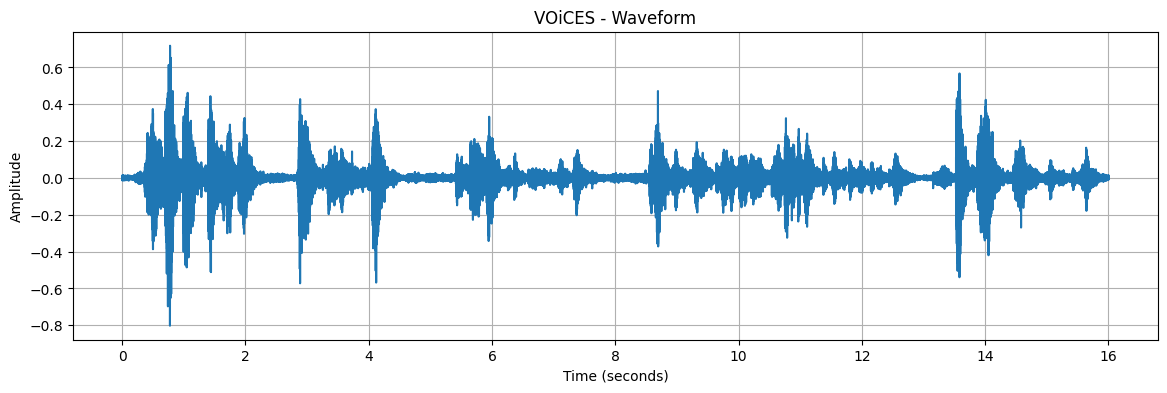

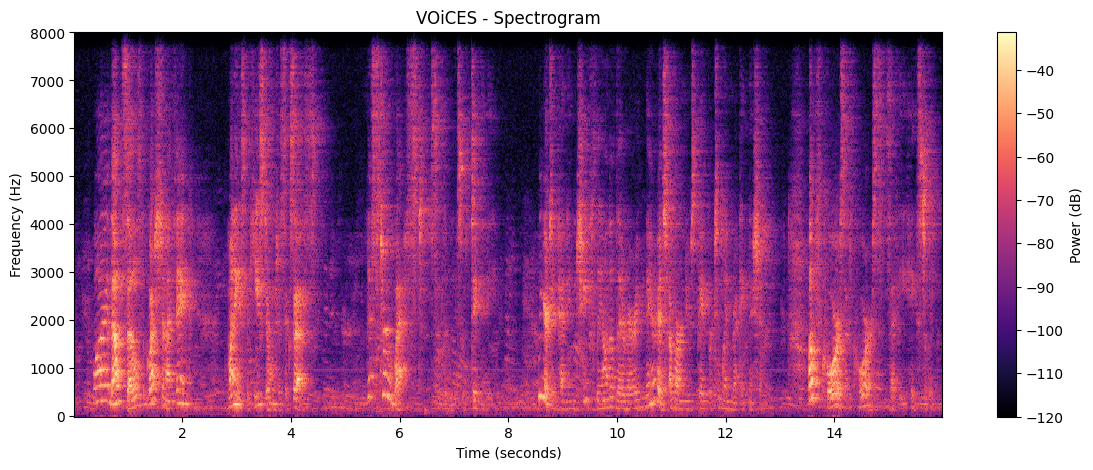

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# Convert stereo to mono if needed
if audio.ndim == 2:
    mono_audio = audio.mean(axis=1)
else:
    mono_audio = audio

# Waveform
time = np.arange(len(mono_audio)) / sample_rate

plt.figure(figsize=(14, 4))
plt.plot(time, mono_audio)
plt.title("VOiCES - Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# Spectrogram
f, t, S = spectrogram(
    mono_audio,
    fs=sample_rate,
    nperseg=512,
    noverlap=384
)

plt.figure(figsize=(14, 5))
plt.pcolormesh(
    t, f,
    10 * np.log10(S + 1e-12),
    shading="auto",
    cmap="magma"
)

plt.title("VOiCES - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")
plt.show()


## الخطوة 6 — قراءة ملف المعلومات المرجعية CSV
**الهدف:** معرفة البيانات الوصفية المتاحة للتسجيلات.

- `pd.read_csv()` يقرأ `Lab41-SRI-VOiCES_ref_SUBSET.csv`.
- **الناتج المحفوظ:** **1500 صف وعمودان**: `fileName` لاسم التسجيل، و`trnscrpt` للنص المنطوق.
- لا يحتوي هذان العمودان على حدود زمنية محددة لبداية الكلام ونهايته؛ لذلك لا يكفي ملف CSV هذا وحده لحساب دقة VAD على مستوى الإطارات.
- رموز الخلفية مثل `babb` و`musi` موجودة في أسماء الملفات ويمكن استخدامها لتصنيف الخلفية على مستوى التسجيل.


In [ ]:

import pandas as pd

# Load VOiCES metadata
csv_path = "/content/VOiCES-subset/Lab41-SRI-VOiCES_ref_SUBSET.csv"

df = pd.read_csv(csv_path)

# Dataset information
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for col in df.columns:
    print(col)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Number of rows: 1500
Number of columns: 2

Column names:
fileName
trnscrpt

First 5 rows:


,fileName,trnscrpt
0,Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg00...,a wink from mister lord must have been intend...
1,Lab41-SRI-VOiCES-rm1-none-sp3549-ch173591-sg00...,but a dull exile in a petty fort by a hot and...
2,Lab41-SRI-VOiCES-rm2-babb-sp4331-ch057179-sg00...,that sir jeffrey had a wife and family she wa...
3,Lab41-SRI-VOiCES-rm2-tele-sp0196-ch122152-sg00...,stop the engines instead of making a row abou...
4,Lab41-SRI-VOiCES-rm2-musi-sp2289-ch152257-sg00...,trib o'ni an to collect and simplify the prin...



Data types:
fileName    object
trnscrpt    object
dtype: object


---
# الجزء الأول — تصنيف الخلفية الصوتية (Background Classification)

التسميات الأربع تعني **نوع الخلفية في التسجيل**: Music وBabble وTelevision وNo Added Noise. لا يعني ذلك كشف توقيت كل حدث داخل الصوت.


## الخطوة 7 — فهرسة التسجيلات وتحديد نوع الخلفية
**الهدف:** إنشاء جدول يربط كل ملف WAV بموقعه داخل الأرشيف وبفئته.

- الكود يمر على الأرشيفات الثمانية ويقرأ **أسماء** ملفات WAV، من دون فك ضغطها كلها.
- يفكك اسم الملف عند `-` ويستخرج إحدى التسميات: `babb` (حديث خلفي)، `musi` (موسيقى)، `tele` (تلفزيون)، `none` (لا توجد ضوضاء مضافة).
- **الناتج المحفوظ:** **909** عناصر منتهية بـ`.wav`؛ التوزيع: Music 231، Babble 228، None 227، Television 223.
- **تنبيه:** هذا تصنيف **الخلفية على مستوى التسجيل** (Recording-level Background Classification)، وليس تحديد بداية ونهاية كل حدث صوتي.


In [ ]:

import os
import tarfile
import pandas as pd

dataset_path = "/content/VOiCES-subset"

# Available labels
noise_codes = ["musi", "none", "babb", "tele"]

# Collect audio files with their original names
audio_records = []

for i in range(1, 9):

    tar_path = os.path.join(
        dataset_path,
        f"VOiCES_90_{i}.tar"
    )

    with tarfile.open(tar_path, "r") as tar:

        for member in tar.getmembers():

            if not member.isfile():
                continue

            if not member.name.lower().endswith(".wav"):
                continue

            filename = os.path.basename(member.name)

            parts = filename.split("-")

            label = next(
                (part for part in parts if part in noise_codes),
                "unknown"
            )

            audio_records.append({
                "archive": f"VOiCES_90_{i}.tar",
                "member_name": member.name,
                "filename": filename,
                "noise_label": label
            })

audio_df = pd.DataFrame(audio_records)

print("Total audio recordings:", len(audio_df))

print("\nNoise distribution:")
print(audio_df["noise_label"].value_counts())

print("\nFirst 10 recordings:")
display(audio_df.head(10))


Total audio recordings: 909

Noise distribution:
noise_label
musi    231
babb    228
none    227
tele    223
Name: count, dtype: int64

First 10 recordings:


,archive,member_name,filename,noise_label
0,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg00...,babb
1,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg00...,tele
2,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg00...,none
3,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-tele-sp5386-ch004145-sg00...,tele
4,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg00...,musi
5,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-none-sp7498-ch099124-sg00...,none
6,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-none-sp0882-ch123268-sg00...,none
7,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-tele-sp6099-ch230928-sg00...,tele
8,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-tele-sp0093-ch126208-sg00...,tele
9,VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-musi-sp6965-ch291718-sg00...,musi


## الخطوة 8 — استخراج MFCC من التسجيلات
**الهدف:** تحويل كل تسجيل صوتي إلى متجه رقمي يمكن للمصنف التعلم منه.

- تُقرأ الملفات مباشرة من TAR باستخدام `tar.extractfile()` و`BytesIO`، ثم `soundfile.read()`.
- تستخرج `librosa` **13 معامل MFCC**؛ ونحسب متوسط كل معامل وانحرافه المعياري عبر إطارات التسجيل: **13 + 13 = 26 خاصية**.
- `X` مصفوفة الخصائص، و`y` تسميات الخلفية؛ `failed_files` يسجل الملفات التي تعذرت قراءتها.
- **الناتج المحفوظ:** `X.shape=(908,26)` و`y.shape=(908,)` مع فشل عنصر واحد.
- ملاحظة منهجية: متوسطات MFCC تلخص التسجيل ولا تحتفظ بالتغير الزمني الدقيق للأحداث الصوتية.


In [ ]:

import os
import tarfile
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from io import BytesIO

# Step 10: Extract MFCC Features

def extract_features(audio, sr):

    # Convert stereo to mono
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # Extract 13 MFCC coefficients
    mfcc = librosa.feature.mfcc(
        y=audio.astype(np.float32),
        sr=sr,
        n_mfcc=13
    )

    # Calculate mean and standard deviation
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # Return 26 features
    return np.concatenate([mfcc_mean, mfcc_std])


X = []
y = []
failed_files = []

# Read all 8 TAR archives
for archive_name, group in audio_df.groupby("archive"):

    tar_path = os.path.join(
        "/content/VOiCES-subset",
        archive_name
    )

    print("Processing:", archive_name)

    with tarfile.open(tar_path, "r") as tar:

        for _, row in group.iterrows():

            try:
                audio_file = tar.extractfile(
                    row["member_name"]
                )

                if audio_file is None:
                    raise ValueError("Audio file not found")

                with audio_file:
                    audio_bytes = audio_file.read()

                audio, sr = sf.read(BytesIO(audio_bytes))

                features = extract_features(audio, sr)

                X.append(features)
                y.append(row["noise_label"])

            except Exception as e:
                failed_files.append(
                    (row["filename"], str(e))
                )

# Convert lists to arrays
X = np.array(X)
y = np.array(y)

print("\nFeature extraction completed!")
print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Failed files:", len(failed_files))

print("\nClass distribution:")
print(pd.Series(y).value_counts())


Processing: VOiCES_90_1.tar
Processing: VOiCES_90_2.tar
Processing: VOiCES_90_3.tar
Processing: VOiCES_90_4.tar
Processing: VOiCES_90_5.tar
Processing: VOiCES_90_6.tar
Processing: VOiCES_90_7.tar
Processing: VOiCES_90_8.tar

Feature extraction completed!
Feature matrix shape: (908, 26)
Labels shape: (908,)
Failed files: 1

Class distribution:
musi    231
babb    228
none    227
tele    222
Name: count, dtype: int64


## الخطوة 9 — تشخيص الملف الذي تعذرت قراءته
**الهدف:** معرفة سبب اختلاف عدد عناصر WAV المكتشفة عن التسجيلات المعالجة فعلاً.

- تعرض الخلية اسم كل ملف فاشل ورسالة الخطأ المقابلة.
- **الناتج المحفوظ:** اسم الملف يبدأ بـ`._Lab41-...wav`، ورسالة `Format not recognised`.
- الملفات البادئة بـ`._` غالباً ملفات **AppleDouble** الوصفية على macOS، وليست WAV صالحة رغم امتداد الاسم.
- لذلك لا نعوّض الخطأ بتسمية متخيلة ولا نعدّ هذا العنصر تسجيلاً صوتياً سليماً.


In [ ]:
print("Number of failed files:", len(failed_files))

for filename, error in failed_files:
    print("Failed file:", filename)
    print("Error:", error)

Number of failed files: 1
Failed file: ._Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav
Error: Error opening <_io.BytesIO object at 0x7e8fd5302fc0>: Format not recognised.


## الخطوة 10 — تنظيف الفهرس وضبط تطابق الخصائص والتسميات
**الهدف:** جعل جدول الملفات مطابقاً لعدد صفوف `X` والتسميات `y`.

- نستبعد الأسماء البادئة بـ`._`، ثم نرتب الفهرس بالترتيب نفسه الذي استخدمه استخراج الخصائص (`groupby("archive")`).
- نتحقق بـ`assert` من تساوي أعداد السجلات ومن تطابق ترتيب الفئات.
- **الناتج المحفوظ:** **909 → 908**، وظهرت رسالة `Dataset alignment verified successfully!`.
- التوزيع النهائي: `musi=231`, `babb=228`, `none=227`, `tele=222`.


In [ ]:

# Step 11: Clean dataset metadata

import numpy as np
import pandas as pd

# Remove macOS metadata files
audio_df_clean = audio_df[
    ~audio_df["filename"].str.startswith("._")
].copy()

# Preserve the same archive order used for MFCC
ordered_df = pd.concat(
    [group for _, group in audio_df_clean.groupby("archive")],
    ignore_index=True
)

print("Original records:", len(audio_df))
print("Clean records:", len(ordered_df))
print("MFCC samples:", len(X))
print("Labels:", len(y))

# Check dataset alignment
assert len(ordered_df) == len(X) == len(y), \
    "Mismatch in number of samples"

assert np.array_equal(
    ordered_df["noise_label"].to_numpy(),
    y
), "Labels are not aligned"

print("\nDataset alignment verified successfully!")

print("\nClass distribution:")
print(ordered_df["noise_label"].value_counts())


Original records: 909
Clean records: 908
MFCC samples: 908
Labels: 908

Dataset alignment verified successfully!

Class distribution:
noise_label
musi    231
babb    228
none    227
tele    222
Name: count, dtype: int64


## الخطوة 11 — تقسيم Train/Test مع فصل المتحدثين
**الهدف:** اختبار قدرة النموذج على التعامل مع تسجيلات لم يستخدمها في التدريب.

- نستخرج `Speaker ID` من الجزء الذي يبدأ بـ`sp` في اسم الملف.
- `GroupShuffleSplit(test_size=0.20, random_state=42)` يفصل **معرّفات المتحدثين** بين التدريب والاختبار.
- **الناتج المحفوظ:** **696 تسجيل تدريب** و**212 تسجيل اختبار**، و`Shared speakers: set()`.
- عدد التسجيلات في الاختبار قد لا يساوي 20% بالضبط؛ التقسيم يعمل على مستوى المجموعات (المتحدثين).
- الانفصال بحسب المتحدث يقلل تسرب الهوية الصوتية، لكنه لا ينفي كل أشكال الترابط الأخرى بين التسجيلات.


In [ ]:

# Step 12: Train/Test Split

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

# Check previous steps
assert "X" in globals(), "Run Step 10 first"
assert "y" in globals(), "Run Step 10 first"
assert "ordered_df" in globals(), "Run Step 11 first"

# Extract Speaker ID from filename
def extract_speaker_id(filename):

    parts = filename.split("-")

    for part in parts:
        if part.startswith("sp") and part[2:].isdigit():
            return part

    return None

# Get speaker IDs
speaker_ids = ordered_df["filename"].apply(
    extract_speaker_id
).to_numpy()

# Verify data
assert len(X) == len(y) == len(speaker_ids), \
    "Data size mismatch"

assert all(s is not None for s in speaker_ids), \
    "Missing speaker IDs"

# Divide data into training and testing sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=speaker_ids)
)

# Training data
X_train = X[train_idx]
y_train = y[train_idx]

# Testing data
X_test = X[test_idx]
y_test = y[test_idx]

# Display results
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(Counter(y_train))

print("\nTesting labels:")
print(Counter(y_test))

# Check speaker overlap
train_speakers = set(speaker_ids[train_idx])
test_speakers = set(speaker_ids[test_idx])

print("\nShared speakers:",
      train_speakers.intersection(test_speakers))

print("\nStep 12 completed successfully!")


Training samples: 696
Testing samples: 212

Training labels:
Counter({np.str_('musi'): 180, np.str_('tele'): 176, np.str_('babb'): 171, np.str_('none'): 169})

Testing labels:
Counter({np.str_('none'): 58, np.str_('babb'): 57, np.str_('musi'): 51, np.str_('tele'): 46})

Shared speakers: set()

Step 12 completed successfully!


## الخطوة 12 — تدريب Random Forest وتقييمه
**الهدف:** إنشاء خط أساس لتصنيف أربع خلفيات صوتية.

- `RandomForestClassifier(n_estimators=100)` يتعلم من 26 خاصية MFCC لكل تسجيل.
- `fit()` للتدريب و`predict()` لتوقع تسميات مجموعة الاختبار.
- **النتيجة المحفوظة:** **Accuracy = 59.91%** على 212 تسجيلاً؛ **Macro F1 ≈ 0.5825**.
- **أفضل Recall لفئة `babb`: 0.91**، بينما أداء فئة `tele` أضعف (F1≈0.44).
- معاني المقاييس: Accuracy نسبة التوقعات الصحيحة؛ Precision دقة التوقعات الموجبة للفئة؛ Recall نسبة اكتشاف أفراد الفئة؛ F1 موازنة Precision وRecall.


In [ ]:

# Step 13: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Check training and testing data
required = ["X_train", "X_test", "y_train", "y_test"]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run Step 12 first. Missing variables: "
        + ", ".join(missing)
    )

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict test labels
y_pred = rf_model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Training Completed!")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["babb", "musi", "none", "tele"],
    zero_division=0
))


Random Forest Training Completed!
Accuracy: 59.91%

Classification Report:
              precision    recall  f1-score   support

        babb       0.69      0.91      0.79        57
        musi       0.66      0.45      0.53        51
        none       0.64      0.52      0.57        58
        tele       0.40      0.48      0.44        46

    accuracy                           0.60       212
   macro avg       0.60      0.59      0.58       212
weighted avg       0.61      0.60      0.59       212



## الخطوة 13 — فهم Confusion Matrix
**الهدف:** رؤية الفئات التي يخلط النموذج بينها بدلاً من الاكتفاء بقيمة Accuracy.

- الصفوف للفئة **الحقيقية**، والأعمدة للفئة **المتوقعة**؛ الأرقام القطرية صحيحة.
- **المصفوفة المحفوظة** بحسب الترتيب `babb,musi,none,tele`:

  `[[52,0,1,4], [8,23,10,10], [2,7,30,19], [13,5,6,22]]`

- مجموع القطر: **52+23+30+22 = 127** من **212**، أي **59.91%**.
- مثال: **19** تسجيلاً من `none` توقعها النموذج `tele`؛ و**13** تسجيلاً من `tele` توقعها `babb`.


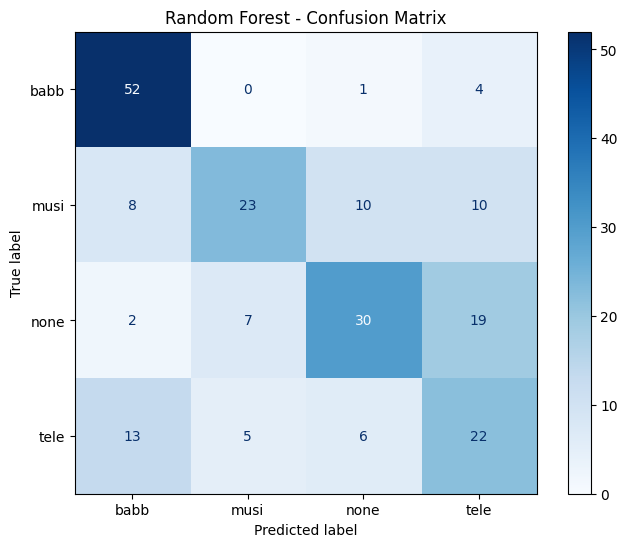

Confusion Matrix:
[[52  0  1  4]
 [ 8 23 10 10]
 [ 2  7 30 19]
 [13  5  6 22]]


In [ ]:

# Step 14: Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

class_names = ["babb", "musi", "none", "tele"]

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


## الخطوة 14 — تدريب SVM ومقارنة النموذجين
**الهدف:** اختبار مصنف بديل على **نفس** تقسيم التدريب والاختبار.

- `StandardScaler` يوحد مقياس خصائص MFCC، و`SVC(kernel="rbf")` يتعلم حدود فصل غير خطية.
- استخدام `Pipeline` يجعل التقييس يُتعلم من بيانات التدريب أثناء `fit()`، بدلاً من تقييس جميع البيانات قبل الفصل.
- **النتيجة المحفوظة:** دقة **SVM = 64.62%**، مقابل **Random Forest = 59.91%**؛ تحسن **4.72 نقطة مئوية تقريباً**.
- **Macro F1:** SVM نحو **0.6353** مقابل RF نحو **0.5825**.
- الاستنتاج محدود بهذه البيانات والإعدادات؛ لا يعني تفوق SVM في كل تطبيق.


In [ ]:

# Step 15: Train and Evaluate SVM

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Create SVM model
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        random_state=42
    ))
])

# Train SVM
svm_model.fit(X_train, y_train)

# Predict test data
svm_pred = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("SVM Training Completed!")
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    labels=["babb", "musi", "none", "tele"],
    zero_division=0
))

# Compare with Random Forest
rf_accuracy = accuracy_score(y_test, y_pred)

print("\nModel Comparison:")
print(f"Random Forest: {rf_accuracy * 100:.2f}%")
print(f"SVM:           {svm_accuracy * 100:.2f}%")


SVM Training Completed!
SVM Accuracy: 64.62%

Classification Report:
              precision    recall  f1-score   support

        babb       0.77      0.89      0.83        57
        musi       0.77      0.47      0.59        51
        none       0.67      0.64      0.65        58
        tele       0.42      0.54      0.47        46

    accuracy                           0.65       212
   macro avg       0.66      0.64      0.64       212
weighted avg       0.67      0.65      0.65       212


Model Comparison:
Random Forest: 59.91%
SVM:           64.62%


---
# الجزء الثاني — اكتشاف فترات الكلام (Voice Activity Detection)

تجارب VAD أدناه على **تسجيل واحد** مدته نحو 16 ثانية؛ وهي دراسة تطبيقية أولية وليست تقييماً شاملاً على كل تسجيلات VOiCES.


## الخطوة 15 — تجربة VAD باستخدام طاقة RMS
**الهدف:** بناء طريقة أولية لاكتشاف النشاط الصوتي داخل **تسجيل واحد** مدته نحو 16 ثانية.

- كل إطار طوله **25 ms**، مع انتقال **10 ms** بين الإطارات.
- نحسب RMS، ثم نحدد العتبة `0.20 * max(rms)` ونصنف ما فوقها نشاطاً.
- **الناتج المحفوظ:** العتبة **0.05531**؛ **279 إطار نشاط** مقابل **1320 إطاراً دون العتبة** من أصل 1599، بنسبة **17.45%**.
- **تنبيه أساسي:** RMS هنا يقيس **نشاطاً فوق عتبة الطاقة**، وليس تحققاً علمياً من وجود كلام بشري.


Sample Rate: 16000
Duration: 16.0 seconds
Threshold: 0.05531
Speech/Activity frames: 279
Non-Speech frames: 1320


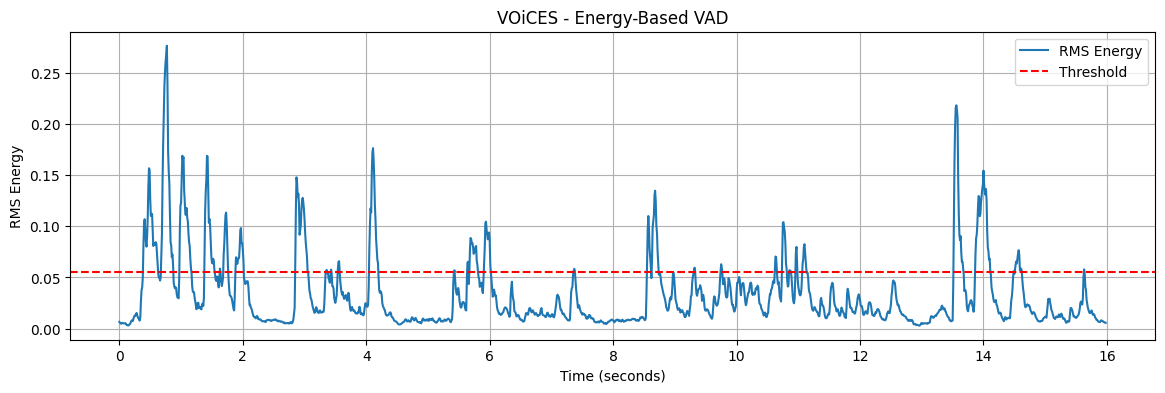

In [ ]:

# Step 16: Basic Voice Activity Detection (VAD)

import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Load audio
audio_path = "/content/voices_samples/sample_1.wav"

audio, sr = sf.read(audio_path)

# Convert to mono if needed
if audio.ndim == 2:
    audio = audio.mean(axis=1)

# Calculate RMS energy
frame_length = int(0.025 * sr)
hop_length = int(0.010 * sr)

rms = librosa.feature.rms(
    y=audio.astype(np.float32),
    frame_length=frame_length,
    hop_length=hop_length,
    center=False
)[0]

# Time axis
times = (
    np.arange(len(rms)) * hop_length
) / sr

# Energy threshold
threshold = 0.20 * np.max(rms)

# Binary activity detection
vad_labels = (rms > threshold).astype(int)

print("Sample Rate:", sr)
print("Duration:", round(len(audio) / sr, 2), "seconds")
print("Threshold:", round(threshold, 5))
print("Speech/Activity frames:", np.sum(vad_labels == 1))
print("Non-Speech frames:", np.sum(vad_labels == 0))

# Plot RMS energy and threshold
plt.figure(figsize=(14, 4))

plt.plot(times, rms, label="RMS Energy")
plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.title("VOiCES - Energy-Based VAD")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS Energy")
plt.legend()
plt.grid(True)
plt.show()


## الخطوة 16 — إسقاط نتائج RMS على Waveform
**الهدف:** فهم مواضع النشاط المكتشف في التسجيل الأصلي.

- الخط الرمادي هو Waveform؛ والمناطق الخضراء هي الإطارات التي تجاوزت RMS عتبتها.
- `axvspan()` يرسم منطقة زمنية لكل إطار فعال؛ كثرة الشرائط الخضراء تعكس القرارات على الإطارات القصيرة.
- يمكن أن يكون الكلام الهادئ أسفل العتبة، كما يمكن أن تكون الضوضاء العالية فوقها؛ لذلك لا يعد هذا الرسم وحده حكماً على جودة VAD.


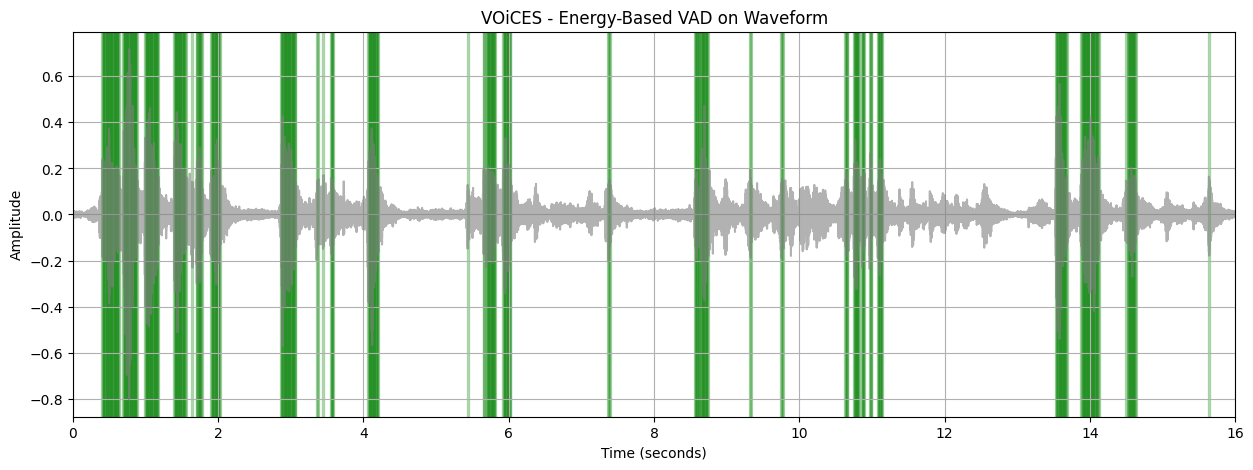

In [ ]:

# Step 17: Visualize VAD on Waveform

import numpy as np
import matplotlib.pyplot as plt

# Time axis of original audio
audio_time = np.arange(len(audio)) / sr

plt.figure(figsize=(15, 5))

# Plot original waveform
plt.plot(
    audio_time,
    audio,
    color="gray",
    alpha=0.6,
    label="Original Waveform"
)

# Highlight detected activity frames
frame_duration = frame_length / sr

for i, label in enumerate(vad_labels):

    if label == 1:

        start_time = times[i]
        end_time = start_time + frame_duration

        plt.axvspan(
            start_time,
            end_time,
            color="green",
            alpha=0.25
        )

plt.title("VOiCES - Energy-Based VAD on Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, len(audio) / sr)
plt.grid(True)
plt.show()


## الخطوة 17 — تثبيت WebRTC VAD
**الهدف:** إضافة مكتبة تتخصص في اتخاذ قرار كلام / غير كلام.

- الأمر `pip install webrtcvad-wheels` يثبت نسخة قابلة للاستيراد باسم `webrtcvad`.
- هذه خلية تجهيز بيئة، وليست تدريب نموذج جديد.
- يلزم تشغيلها مرة أخرى في جلسات Colab الجديدة إذا لم تكن المكتبة مثبتة.


In [ ]:

!pip -q install webrtcvad-wheels


## الخطوة 18 — كشف الكلام باستخدام WebRTC VAD
**الهدف:** مقارنة الكاشف المتخصص مع طريقة RMS على التسجيل نفسه.

- يحول الصوت إلى **PCM 16-bit** ثم يقسمه إلى إطارات **30 ms** غير متداخلة.
- `Vad(2)` يختار مستوى حساسية/صرامة متوسط، و`is_speech()` يصنف كل إطار.
- **الناتج المحفوظ:** **533 إطاراً**؛ **431 Speech** و**102 Non-speech**.
- المخطط الأخضر يوضح **الكلام المحتمل**، وقد يشمل متحدثين في الخلفية، وليس بالضرورة المتحدث الأساسي فقط.


Total frames: 533
Speech frames: 431
Non-speech frames: 102


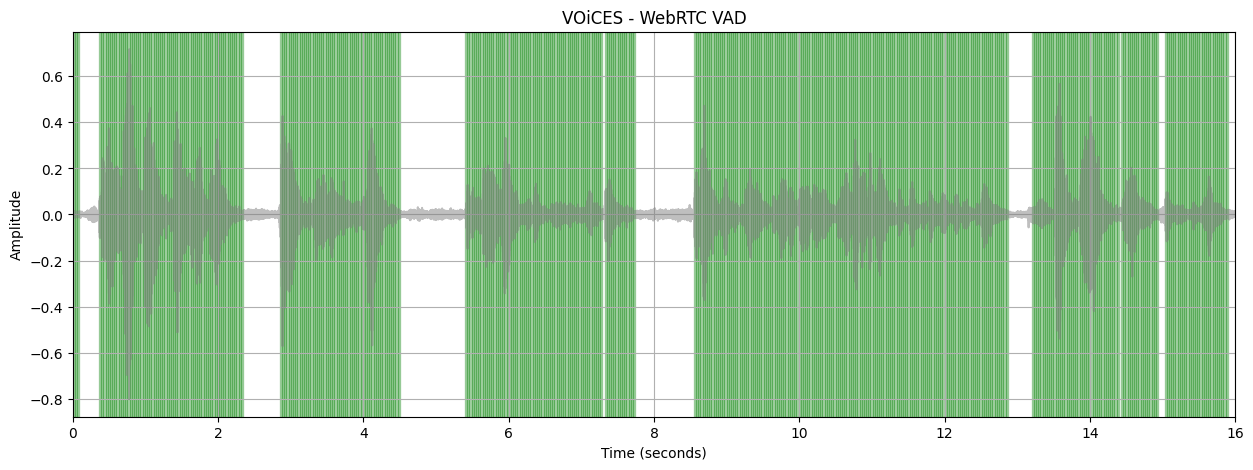

In [ ]:

# Step 18: WebRTC Voice Activity Detection

import webrtcvad
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

# Read audio
audio_path = "/content/voices_samples/sample_1.wav"

audio, sr = sf.read(audio_path)

if audio.ndim == 2:
    audio = audio.mean(axis=1)

# WebRTC supports 8000, 16000, 32000, 48000 Hz
assert sr in [8000, 16000, 32000, 48000], \
    "Unsupported sample rate"

# Convert float audio to 16-bit PCM
audio_pcm = np.int16(
    np.clip(audio, -1, 1) * 32767
)

# WebRTC VAD mode: 0 (least aggressive) to 3
vad = webrtcvad.Vad(2)

# Frame duration = 30 ms
frame_duration_ms = 30
frame_size = int(sr * frame_duration_ms / 1000)

speech_frames = []
frame_times = []

for start in range(0, len(audio_pcm) - frame_size + 1, frame_size):

    frame = audio_pcm[start:start + frame_size]

    is_speech = vad.is_speech(
        frame.tobytes(),
        sr
    )

    speech_frames.append(int(is_speech))
    frame_times.append(start / sr)

speech_frames = np.array(speech_frames)
frame_times = np.array(frame_times)

print("Total frames:", len(speech_frames))
print("Speech frames:", np.sum(speech_frames == 1))
print("Non-speech frames:", np.sum(speech_frames == 0))

# Plot waveform with speech regions
time_axis = np.arange(len(audio)) / sr

plt.figure(figsize=(15, 5))
plt.plot(time_axis, audio, color="gray", alpha=0.5)

for i, label in enumerate(speech_frames):
    if label == 1:
        plt.axvspan(
            frame_times[i],
            frame_times[i] + frame_duration_ms / 1000,
            color="green",
            alpha=0.3
        )

plt.title("VOiCES - WebRTC VAD")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, len(audio) / sr)
plt.grid(True)
plt.show()


## الخطوة 19 — مقارنة نسب الكشف بين RMS وWebRTC
**الهدف:** تلخيص مقدار النشاط الذي تصنفه كل طريقة.

- **RMS:** 279 من 1599 إطاراً = **17.45%**.
- **WebRTC:** 431 من 533 إطاراً = **80.86%**.
- لأن طول/تداخل الإطارات مختلف، تُقارَن النسب الوصفية بدلاً من مقارنة الأعداد الخام مباشرة.
- **تحذير:** نسبة 80.86% هي نسبة إطارات موسومة كلاماً، **وليست Accuracy** أو دليلاً على أن WebRTC أدق.


VAD Comparison:


,Method,Total Frames,Detected Frames,Detected (%)
0,RMS Energy,1599,279,17.45
1,WebRTC VAD,533,431,80.86


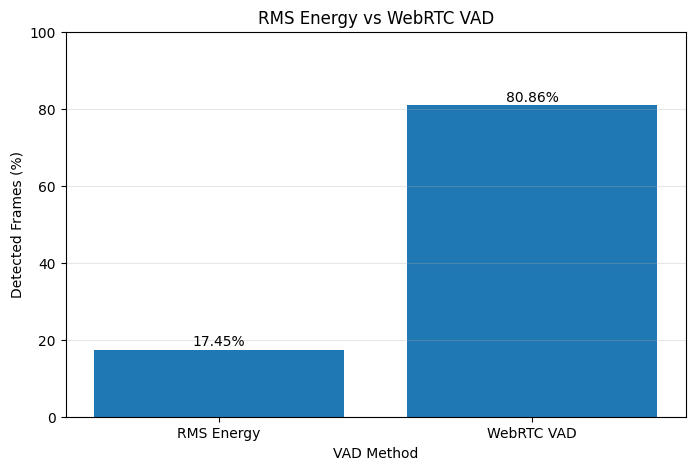

In [ ]:

# Step 19: RMS VAD vs WebRTC VAD

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# RMS activity results
rms_total = len(vad_labels)
rms_active = np.sum(vad_labels == 1)
rms_percentage = 100 * rms_active / rms_total

# WebRTC speech results
webrtc_total = len(speech_frames)
webrtc_active = np.sum(speech_frames == 1)
webrtc_percentage = 100 * webrtc_active / webrtc_total

# Create comparison table
comparison = pd.DataFrame({
    "Method": ["RMS Energy", "WebRTC VAD"],
    "Total Frames": [rms_total, webrtc_total],
    "Detected Frames": [rms_active, webrtc_active],
    "Detected (%)": [rms_percentage, webrtc_percentage]
})

print("VAD Comparison:")
display(comparison.round(2))

# Plot comparison
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison["Method"],
    comparison["Detected (%)"]
)

plt.title("RMS Energy vs WebRTC VAD")
plt.xlabel("VAD Method")
plt.ylabel("Detected Frames (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, comparison["Detected (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()


## الخطوة 20 — قياس اتفاق قرارات الطريقتين
**الهدف:** معرفة عدد الفترات التي تتفق فيها الطريقتان، بعد مواءمة القرارات زمنياً.

- تُحوَّل قرارات RMS المتداخلة إلى إطارات WebRTC ذات 30 ms باستخدام أغلبية الإطارات المتقاطعة.
- **الناتج المحفوظ:** اتفاق **36.59%**؛ `Cohen's Kappa=0.0953`، أي اتفاق ضعيف.
- جدول المقارنة (صف RMS، عمود WebRTC): `[[102,338],[0,93]]`؛ اتفقتا في `102+93=195` إطاراً من أصل 533.
- **338** إطاراً رآها WebRTC كلاماً بينما بقيت تحت معيار نشاط RMS.
- الاتفاق يقيس التشابه بين **تنبؤين**، ولا يقيس الدقة دون بيانات Ground Truth.


In [ ]:

# Step 20: Agreement Between RMS and WebRTC VAD

import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# RMS frame intervals
rms_starts = times
rms_ends = times + frame_length / sr

# WebRTC frame intervals
webrtc_starts = frame_times
webrtc_ends = frame_times + 0.030

# Align RMS decisions to WebRTC frames
rms_aligned = []

for start, end in zip(webrtc_starts, webrtc_ends):

    overlaps = (rms_starts < end) & (rms_ends > start)

    if overlaps.any():
        activity = np.mean(vad_labels[overlaps])
        rms_aligned.append(int(activity >= 0.5))
    else:
        rms_aligned.append(0)

rms_aligned = np.array(rms_aligned)

# Compare predictions
agreement = np.mean(
    rms_aligned == speech_frames
) * 100

kappa = cohen_kappa_score(
    rms_aligned,
    speech_frames
)

comparison_table = pd.crosstab(
    pd.Series(rms_aligned, name="RMS"),
    pd.Series(speech_frames, name="WebRTC")
)

print("Agreement:", round(agreement, 2), "%")
print("Cohen's Kappa:", round(kappa, 4))

print("\nComparison Table:")
display(comparison_table)


Agreement: 36.59 %
Cohen's Kappa: 0.0953

Comparison Table:


WebRTC,0,1
RMS,,
0,102,338
1,0,93


## الخطوة 21 — استخراج فترات الكلام الأولية
**الهدف:** تحويل قرارات WebRTC الثنائية إلى أزمنة بداية ونهاية قابلة للقراءة.

- عند الانتقال من 0 إلى 1 يبدأ المقطع، وعند العودة إلى 0 ينتهي.
- **الناتج المحفوظ:** **9 فترات أولية** بإجمالي **12.93 ثانية**.
- من أمثلتها: `0.36–2.34`، `8.55–12.87`، ويوجد مقطع قصير جداً `0.00–0.09`.
- هذه الفترات **مكتشفة آلياً**، ولم تُراجع مقابل وسم زمني بشري.


In [ ]:

# Step 21: Extract Speech Segments from WebRTC VAD

import numpy as np
import pandas as pd

frame_duration = frame_duration_ms / 1000

speech_segments = []
start_time = None

for i, label in enumerate(speech_frames):

    if label == 1 and start_time is None:
        start_time = frame_times[i]

    elif label == 0 and start_time is not None:
        end_time = frame_times[i]
        speech_segments.append(
            (start_time, end_time)
        )
        start_time = None

# Handle a speech segment reaching the last frame
if start_time is not None:
    speech_segments.append(
        (start_time, frame_times[-1] + frame_duration)
    )

segments_df = pd.DataFrame(
    speech_segments,
    columns=["Start (s)", "End (s)"]
)

segments_df["Duration (s)"] = (
    segments_df["End (s)"] -
    segments_df["Start (s)"]
)

print("Number of speech segments:", len(segments_df))

print("\nDetected Speech Segments:")
display(segments_df.round(2))

print(
    "\nTotal detected speech duration:",
    round(segments_df["Duration (s)"].sum(), 2),
    "seconds"
)


Number of speech segments: 9

Detected Speech Segments:


,Start (s),End (s),Duration (s)
0,0.00,0.09,0.09
1,0.36,2.34,1.98
2,2.85,4.50,1.65
3,5.40,7.29,1.89
4,7.32,7.74,0.42
5,8.55,12.87,4.32
6,13.20,14.40,1.20
7,14.43,14.94,0.51
8,15.03,15.90,0.87



Total detected speech duration: 12.93 seconds


## الخطوة 22 — معالجة الفترات اللاحقة (Post-processing)
**الهدف:** دمج الانقطاعات القصيرة وإزالة الاكتشافات الأقصر من حد أدنى.

- `max_gap=0.15` ثانية: دمج فترتين إن كانت الفجوة بينهما **≤ 0.15 s**.
- `min_duration=0.20` ثانية: حذف الفترات القصيرة جداً بعد الدمج.
- **الناتج المحفوظ:** تقلص عدد المقاطع من **9 إلى 5**؛ مدتها المجمعة **12.99 ثانية**.
- الفرق في إجمالي المدة يرجع إلى إدراج فجوات قصيرة داخل المقاطع المدمجة، وليس إلى اكتشاف كلام جديد مؤكد.


In [ ]:

# Step 22: VAD Post-processing

import pandas as pd

# Configuration
max_gap = 0.15
min_duration = 0.20

# Convert speech segments to a list
segments = speech_segments.copy()

# Merge close segments
merged_segments = []

for start, end in segments:

    if not merged_segments:
        merged_segments.append([start, end])

    else:
        previous_end = merged_segments[-1][1]

        gap = start - previous_end

        if gap <= max_gap:
            merged_segments[-1][1] = max(
                previous_end, end
            )
        else:
            merged_segments.append([start, end])

# Remove very short segments
clean_segments = [
    (start, end)
    for start, end in merged_segments
    if (end - start) >= min_duration
]

# Create results table
clean_df = pd.DataFrame(
    clean_segments,
    columns=["Start (s)", "End (s)"]
)

clean_df["Duration (s)"] = (
    clean_df["End (s)"] - clean_df["Start (s)"]
)

print("Original speech segments:", len(segments))
print("After post-processing:", len(clean_segments))

print("\nClean Speech Segments:")
display(clean_df.round(2))

print(
    "\nTotal clean speech duration:",
    round(clean_df["Duration (s)"].sum(), 2),
    "seconds"
)


Original speech segments: 9
After post-processing: 5

Clean Speech Segments:


,Start (s),End (s),Duration (s)
0,0.36,2.34,1.98
1,2.85,4.50,1.65
2,5.40,7.74,2.34
3,8.55,12.87,4.32
4,13.20,15.90,2.70



Total clean speech duration: 12.99 seconds


## الخطوة 23 — رسم فترات الكلام النهائية
**الهدف:** تقديم شكل بصري واضح يمكن إضافته إلى التقرير.

- Waveform بالرمادي؛ والتظليل الأخضر يغطي الفترات الخمس بعد التنظيف.
- **الحدود النهائية المحفوظة (ثانية):** `0.36–2.34`، `2.85–4.50`، `5.40–7.74`، `8.55–12.87`، `13.20–15.90`.
- هذه حدود **نتيجة الخوارزمية**، وليست Ground Truth؛ وقد يشمل الكشف الكلام الخلفي.


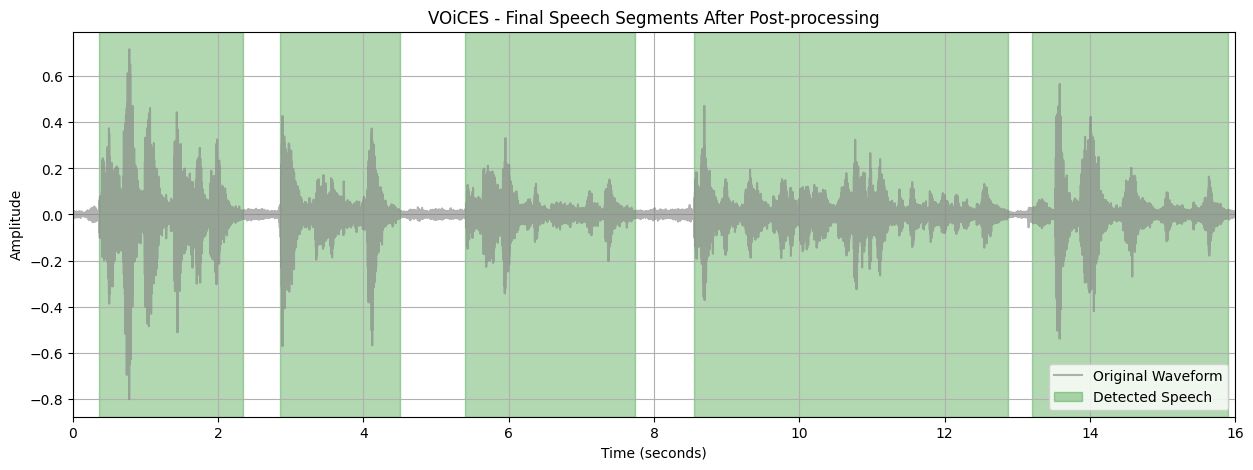

In [ ]:
# Step 23: Visualize Final Clean Speech Segments

import numpy as np
import matplotlib.pyplot as plt

# Time axis
time_axis = np.arange(len(audio)) / sr

plt.figure(figsize=(15, 5))

# Original waveform
plt.plot(
    time_axis,
    audio,
    color="gray",
    alpha=0.6,
    label="Original Waveform"
)

# Highlight final clean speech segments
for i, (start, end) in enumerate(clean_segments):
    plt.axvspan(
        start,
        end,
        color="green",
        alpha=0.30,
        label="Detected Speech" if i == 0 else None
    )

plt.title("VOiCES - Final Speech Segments After Post-processing")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, len(audio) / sr)
plt.legend()
plt.grid(True)
plt.show()

## الخطوة 24 — تلخيص نتائج مهمتي
**الهدف:** جمع النتائج العددية في جدولين مستقلين.

**Part A — تصنيف الخلفية:** استخدمنا **908 تسجيلات**، منها **696 تدريب** و**212 اختبار**. RF: **59.9057%** / Macro F1 **0.5825**؛ SVM: **64.6226%** / Macro F1 **0.6353**.

**Part B — VAD:** التجربة الحالية على تسجيل **16.005 s** فقط. RMS: **17.4484%** نشاط؛ WebRTC: **80.8630%** كلام متوقع؛ اتفاق **36.5854%**؛ كابا **0.0953**؛ **5** فترات نهائية بإجمالي **12.99 s**.

**حدود التقييم:** لا توجد في هذه التجربة وسوم زمنية مرجعية لحساب Precision/Recall/F1 لـVAD، فلا نكتب أن 80.86% «دقة كشف الكلام». كذلك تصنيف Music/Babble/TV/None على مستوى التسجيل يُعد تطبيقاً لتصنيف خلفيات صوتية، لا اكتشاف توقيت جميع الأحداث.


In [ ]:

# Step 24: Final Assignment Results Summary

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Part A: Background Classification
model_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM"],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, svm_pred) * 100
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, svm_pred, average="macro")
    ]
})

print("PART A: Background Classification")
print("Total valid recordings:", len(X))
print("Training recordings:", len(X_train))
print("Testing recordings:", len(X_test))
display(model_results.round(4))

# Part B: Voice Activity Detection
vad_results = pd.DataFrame({
    "Metric": [
        "Audio duration (s)",
        "RMS activity (%)",
        "WebRTC speech (%)",
        "VAD agreement (%)",
        "Cohen's Kappa",
        "Final speech segments",
        "Final detected speech duration (s)"
    ],
    "Value": [
        len(audio) / sr,
        rms_percentage,
        webrtc_percentage,
        agreement,
        kappa,
        len(clean_segments),
        sum(end - start for start, end in clean_segments)
    ]
})

print("\nPART B: Voice Activity Detection")
display(vad_results.round(4))


PART A: Background Classification
Total valid recordings: 908
Training recordings: 696
Testing recordings: 212


,Model,Accuracy (%),Macro F1
0,Random Forest,59.9057,0.5825
1,SVM,64.6226,0.6353



PART B: Voice Activity Detection


,Metric,Value
0,Audio duration (s),16.0050
1,RMS activity (%),17.4484
2,WebRTC speech (%),80.8630
3,VAD agreement (%),36.5854
4,Cohen's Kappa,0.0953
5,Final speech segments,5.0000
6,Final detected speech duration (s),12.9900


---
## الاستنتاج النهائي والتفسير الأكاديمي

- نجح إعداد **908 تسجيلات** بعد تجاوز عنصر غير صوتي يبدأ بـ`._`، مع فصل معرفات المتحدثين بين التدريب والاختبار.
- في **تصنيف الخلفية** حقق SVM دقة **64.62%** مقابل **59.91%** لـRandom Forest، وهو تحسن على بيانات الاختبار الحالية.
- في تجربة **VAD** كشف RMS نشاطاً في **17.45%** من إطاراته، وصنف WebRTC **80.86%** من إطاراته كلاماً؛ وكان اتفاق الطريقتين **36.59%**، و`Kappa=0.0953`.
- بعد المعالجة اللاحقة حُددت **5 فترات كلام محتمل** بإجمالي **12.99 ثانية** على التسجيل المختبر.

